# 02 · Normal bivariante con correlación alta (E2)

Repetimos el estudio del cuaderno 01 con una nube muy alargada en dirección diagonal. Comparamos el orden que induce
la longitud de ruta media $\bar h_t(\mathbf{x})$ de *iForest* y del EIF con el de la profundidad de Tukey muestral
$HD(\mathbf{x}, P_n)$, con la configuración estándar ($t = 100$, $\psi = 256$, $h_{lim} = \psi - 1$) y las mismas
medidas de asociación, que se explican en el cuaderno 01.

La correlación es intencionada: los cortes de iForest son paralelos a los ejes, mientras que la nube está alargada en
una dirección oblicua. La primera parte estudia la primera réplica de `experiments/E2.py` y la segunda resume las
100 réplicas.

In [1]:
import random
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from isolation_forest import iforest, itree, longitudes, c
from eif import eif, eif_arbol, longitudes_eif
from escenarios import normal
from profundidad import hd_muestral
from metricas import metricas_par
import visualizacion as V

PSI, T, HLIM = 256, 100, 255
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)


def bosques(X, semilla, t=T):
    # Longitudes de ruta (matriz n x t) de iForest y del EIF, con la semilla de la réplica
    random.seed(semilla)
    H_if = longitudes(X, iforest(X, t=t, psi=PSI), HLIM)
    random.seed(semilla)
    H_eif = longitudes_eif(X, eif(X, t=t, psi=PSI), HLIM)
    return {"iForest": H_if, "EIF": H_eif}


def medidas(h, hd, hd_P):
    # Medidas de la memoria frente a HD(x, P_n) y el techo (log HD_P, como en src/experimento.py)
    filas = {metodo: metricas_par(h[metodo], hd) for metodo in h}
    filas["Techo (HD poblacional)"] = metricas_par(np.log(hd_P), hd)
    return pd.DataFrame(filas).T.rename(columns=V.MEDIDAS)

## Una réplica

Generamos $n = 1000$ observaciones de $N_2(\boldsymbol{\mu}, \Sigma)$ con
$$
\boldsymbol{\mu} = \begin{pmatrix} 2 \\ -1 \end{pmatrix}, \qquad
\Sigma = \begin{pmatrix} 2 & 1.2 \\ 1.2 & 1 \end{pmatrix},
$$
es decir, varianzas $2$ y $1$ y correlación $1.2/\sqrt{2} \approx 0.85$. La semilla es la de la primera réplica de
E2, $2000$. Como en el cuaderno 01, $\mathbf{x}_{\mathrm{in}}$ y $\mathbf{x}_{\mathrm{out}}$ son las observaciones con
menor y mayor distancia de Mahalanobis.

In [2]:
esc = normal("E2", 1000, [2.0, -1.0], [[2.0, 1.2], [1.2, 1.0]])
semilla = 2000

In [3]:
X, _ = esc.muestrear(np.random.default_rng(semilla))
dM = esc.d_M(X)
i_in, i_out = int(np.argmin(dM)), int(np.argmax(dM))
print(f"x_in = {X[i_in].round(3)},  d_M = {dM[i_in]:.3f}")
print(f"x_out = {X[i_out].round(3)},  d_M = {dM[i_out]:.3f}")

x_in = [ 1.931 -1.042],  d_M = 0.049
x_out = [7.065 2.724],  d_M = 3.808


Representamos la muestra junto con las elipses que contienen el $50\,\%$, el $90\,\%$ y el $99\,\%$ de la
probabilidad. Como $d_M(\mathbf{X})^2 \sim \chi^2_2$, cada elipse es el conjunto
$\{\mathbf{x} : d_M(\mathbf{x})^2 = \chi^2_{2,\alpha}\}$.

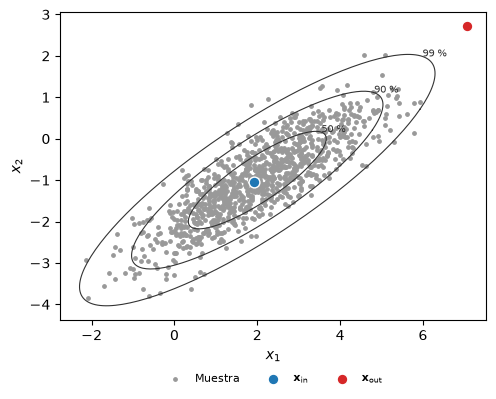

In [4]:
fig = V.dibujar_muestra(X, esc.mu, esc.Sigma, i_in, i_out)
V.guardar(fig, "E2_muestra")
plt.show()

### Cómo aísla un árbol

Construimos un único árbol de cada método sobre una submuestra de tamaño $\psi = 256$ formada por
$\mathbf{x}_{\mathrm{in}}$, $\mathbf{x}_{\mathrm{out}}$ y 254 observaciones más elegidas al azar. Recorriendo el
árbol con un punto, cada nodo interno que atraviesa corta la región en la que se encuentra, hasta que el punto queda
solo en la suya. Como los árboles se construyen completos y las observaciones son distintas, el número de cortes
coincide con la longitud de ruta $h(\mathbf{x})$. En **iForest** cada corte es una recta paralela a uno de los ejes y
las regiones son rectángulos; en el **EIF** cada corte es una recta de orientación aleatoria y las regiones son
polígonos convexos.

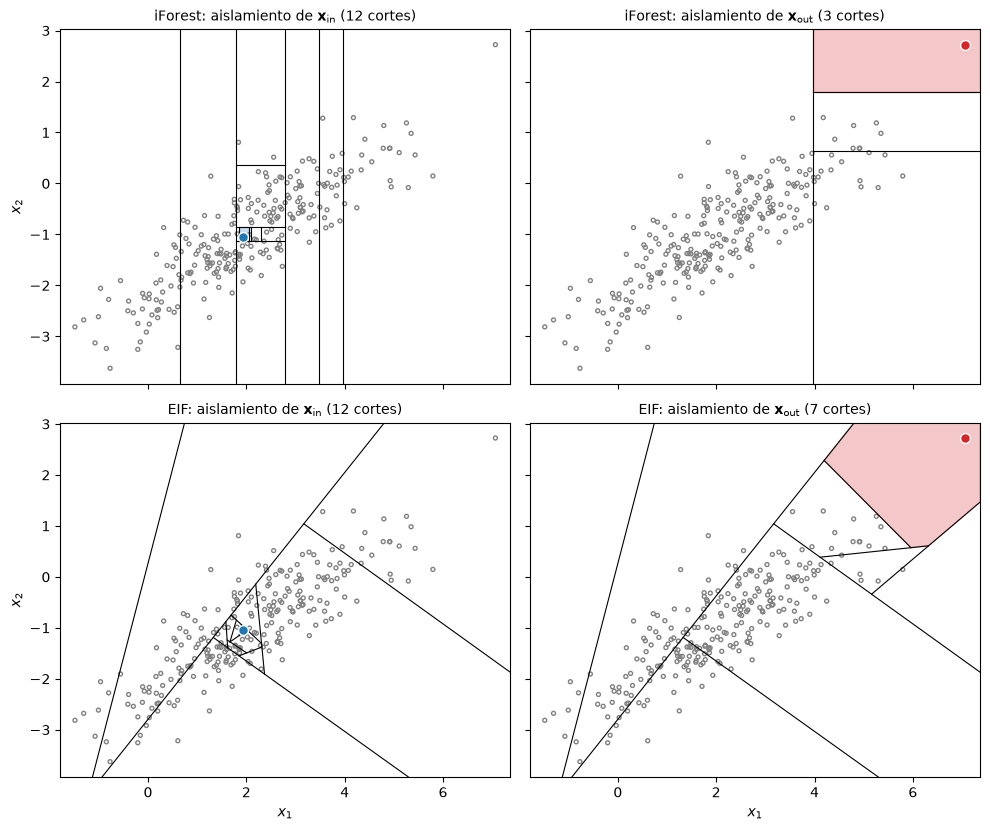

In [5]:
random.seed(semilla + 1)
resto = [j for j in range(len(X)) if j not in (i_in, i_out)]
sub = X[random.sample(resto, PSI - 2) + [i_in, i_out]]
random.seed(semilla + 1)
arboles = {"iForest": itree(sub), "EIF": eif_arbol(sub, nivel=1)}
fig = V.dibujar_aislamiento(sub, arboles, X[i_in], X[i_out])
V.guardar(fig, "E2_aislamiento")
plt.show()

In [6]:
H = bosques(X, semilla)
h = {metodo: M.mean(axis=1) for metodo, M in H.items()}

### Profundidad de Tukey

Calculamos $HD(\mathbf{x}, P_n)$ de forma exacta con la biblioteca *data-depth*. Toma valores en
$\{1/n, 2/n, \dots\}$ (todas las observaciones de la muestra tienen profundidad al menos $1/n$), de modo que hay
muchos empates. Calculamos también la profundidad poblacional $HD(\mathbf{x}, P) = \Phi(-d_M(\mathbf{x}))$, con la
que se obtiene el techo.

In [7]:
hd = hd_muestral(X)
hd_P = esc.hd_P(X)
print(f"HD(x, P_n): mínimo {hd.min():.3f}, máximo {hd.max():.3f}, {len(np.unique(hd))} valores distintos")
print(f"HD(x_in, P_n) = {hd[i_in]:.3f},  HD(x_out, P_n) = {hd[i_out]:.3f}")

HD(x, P_n): mínimo 0.001, máximo 0.476, 356 valores distintos
HD(x_in, P_n) = 0.476,  HD(x_out, P_n) = 0.001


### Comparación con la profundidad de Tukey: dos escalas

La figura siguiente compara $\bar h_t$ con $HD(\cdot, P_n)$ en dos escalas, que responden a preguntas distintas.

- **Fila superior, rangos.** Cada observación se representa por su rango según cada medida, dividido entre $n$
  para llevarlo a $[0, 1]$. Es la escala en la que trabajan $\tau_b$ y $\rho_S$: si las dos medidas ordenasen igual,
  todos los puntos estarían sobre la diagonal. Los rangos reparten las observaciones de forma uniforme y permiten ver
  en qué zona (centro o periferia) se separan los dos órdenes, pero ocultan la forma de la relación.
- **Fila inferior, valores con $HD$ en escala logarítmica.** Se representa el valor de $\bar h_t$ frente a $HD$,
  con el eje horizontal en escala logarítmica. $HD(\cdot, P_n)$ toma los valores $1/n, 2/n, \dots$, que en escala
  lineal se amontonan cerca de $0$ precisamente donde están las observaciones periféricas; la escala logarítmica las
  separa. En esta escala la relación es aproximadamente una recta, $\bar h_t \approx a + b \log HD$, que se ajusta
  por mínimos cuadrados; $r_{\log}$ mide la calidad de ese ajuste. Las bandas verticales de la izquierda son los
  valores $HD = 1/n, 2/n, \dots$ compartidos por varias observaciones.

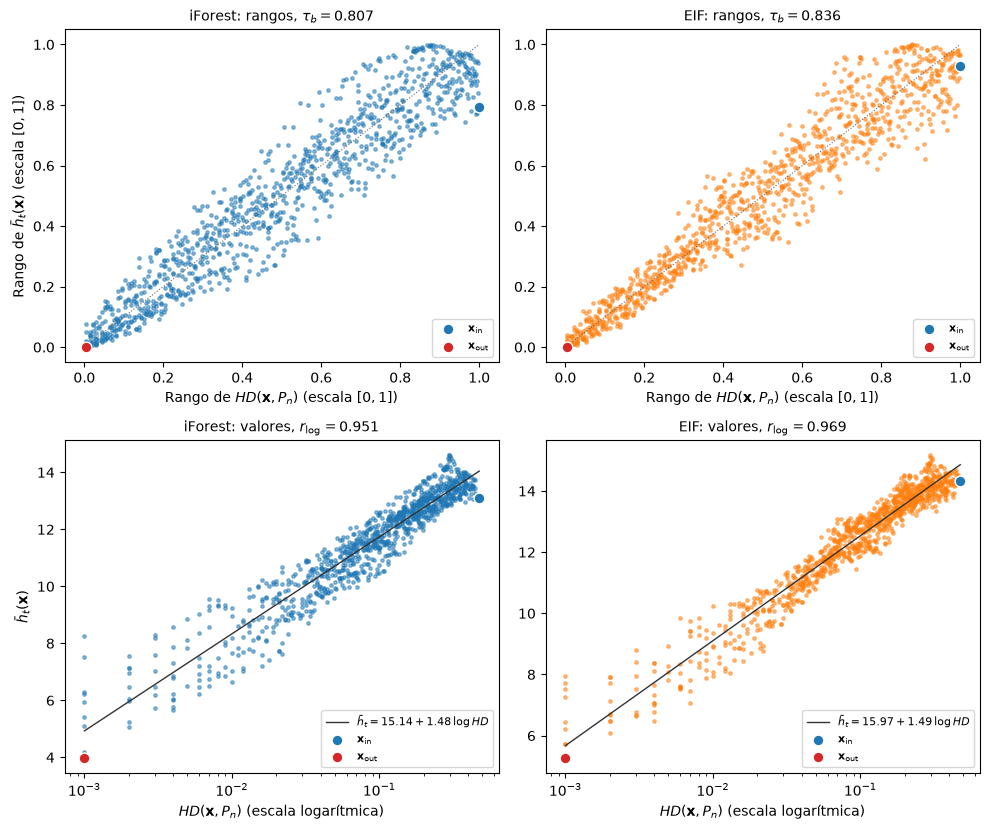

In [8]:
destacados = [(i_in, "tab:blue", r"$\mathbf{x}_{\mathrm{in}}$"), (i_out, "tab:red", r"$\mathbf{x}_{\mathrm{out}}$")]
fig = V.dibujar_h_frente_hd(h, hd, destacados)
V.guardar(fig, "E2_h_frente_hd")
plt.show()

Coloreamos la muestra según el rango de cada medida: los colores claros corresponden a las observaciones más
centrales.

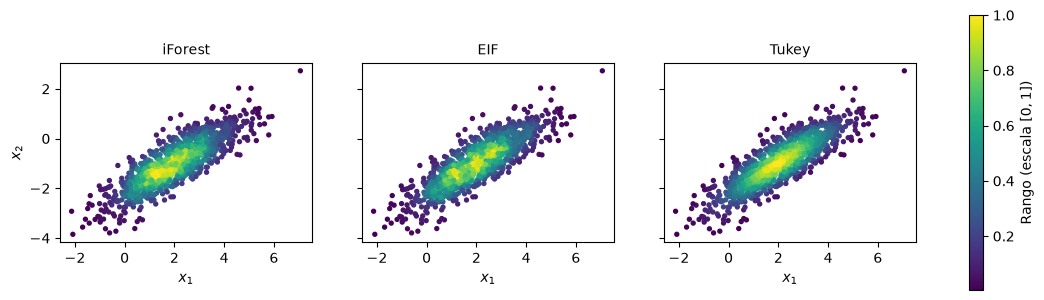

In [9]:
fig = V.dibujar_mapas(X, {"iForest": h["iForest"], "EIF": h["EIF"], "Tukey": hd})
V.guardar(fig, "E2_mapas")
plt.show()

Comparamos las observaciones menos centrales: el $5\,\%$ con menor $\bar h_t$ según cada método frente al
$5\,\%$ con menor profundidad de Tukey. Si hay empates en el punto de corte, se reparten al azar y se calcula el
solapamiento esperado.

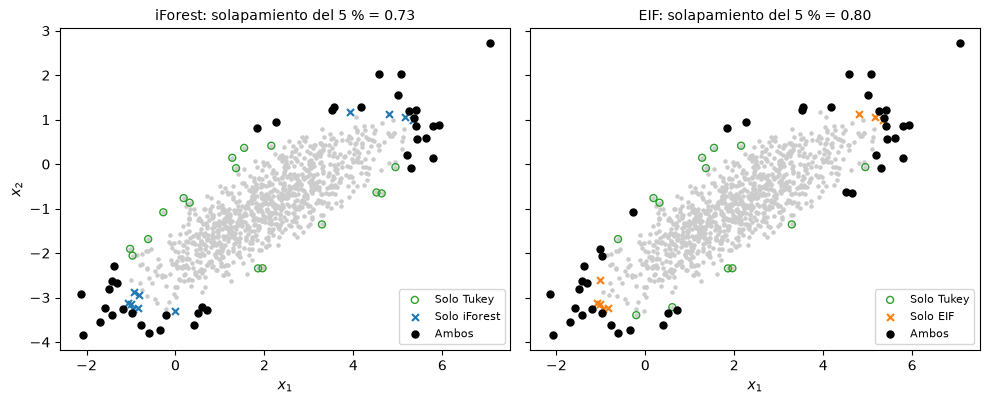

In [10]:
fig = V.dibujar_anomalias(X, h, hd)
V.guardar(fig, "E2_anomalias")
plt.show()

Las medidas de esta réplica coinciden con la fila $r = 0$ de `results/E2.csv`.

In [11]:
medidas(h, hd, hd_P)

,$\tau_b$,$\rho_S$,$r_{\log}$,$\xi_n$,Solapamiento 5 %,$\tau_b$ centro,$\tau_b$ periferia
iForest,0.807,0.954,0.951,0.716,0.730,0.579,0.580
EIF,0.836,0.963,0.969,0.761,0.802,0.603,0.677
Techo (HD poblacional),0.958,0.998,0.988,0.933,0.858,0.933,0.823


## Resultados sobre las 100 réplicas

Una réplica no basta para sacar conclusiones. La tabla resume las $100$ réplicas de E2 (media y, entre
paréntesis, desviación típica), y la siguiente compara los dos métodos réplica a réplica: diferencia media
(EIF menos iForest), número de réplicas en que el EIF obtiene un valor mayor y $p$-valor de la prueba de rangos con
signo de Wilcoxon.

In [12]:
E2 = pd.read_csv("../results/E2.csv")
V.tabla_resumen(E2)

R       $\tau_b$       $\rho_S$     $r_{\log}$        $\xi_n$ Solapamiento 5 % $\tau_b$ centro $\tau_b$ periferia
escenario método                                                                                                                      
E2        Techo    100  0.956 (0.011)  0.997 (0.001)  0.987 (0.006)  0.928 (0.016)    0.888 (0.029)   0.916 (0.027)      0.842 (0.032)
          iForest  100  0.820 (0.022)  0.957 (0.011)  0.948 (0.007)  0.733 (0.029)    0.640 (0.042)   0.594 (0.072)      0.542 (0.040)
          EIF      100  0.830 (0.020)  0.960 (0.010)  0.961 (0.005)  0.749 (0.026)    0.721 (0.050)   0.595 (0.070)      0.642 (0.044)

In [13]:
V.comparacion_pareada(E2, medidas=("tau_b", "r_log", "xi", "sol05"))

diferencia media réplicas a favor del EIF  p de Wilcoxon
escenario medida                                                                    
E2        $\tau_b$                     0.010                 68 / 100      5.584e-05
          $r_{\log}$                   0.013                 98 / 100      7.787e-18
          $\xi_n$                      0.016                 73 / 100      8.953e-07
          Solapamiento 5 %             0.081                 94 / 100      5.231e-17

## Observaciones

- **La $\tau_b$ global apenas cambia respecto de E1** ($0.820$ con iForest y $0.830$ con el EIF), **pero la periferia
  empeora mucho con iForest**: el solapamiento del $5\,\%$ baja a $0.640$ y la $\tau_b$ de la periferia a $0.542$,
  frente a un techo de $0.888$ y $0.842$. El EIF reduce la pérdida ($0.721$ y $0.642$). En el centro los dos métodos
  coinciden ($0.594$ y $0.595$).
- **$r_{\log}$ detecta el problema y $\tau_b$ casi no.** La $\tau_b$ pesa por igual todos los pares, mientras que la
  escala logarítmica separa las profundidades pequeñas. Por eso $r_{\log}$ baja con iForest a $0.948$ (frente a
  $0.969$ en E1) y se mantiene en $0.961$ con el EIF, que es mejor en $98$ de las $100$ réplicas. En la gráfica en
  escala logarítmica, iForest muestra observaciones de profundidad muy pequeña con longitudes de ruta muy por encima
  de la recta: son observaciones periféricas que iForest considera relativamente centrales.
- **La causa es la orientación de la nube.** En la figura de anomalías, las observaciones que solo señala iForest se
  concentran en los extremos del eje mayor de la elipse, y las que solo señala la profundidad de Tukey, en los lados
  largos. Los cortes paralelos a los ejes separan con facilidad las observaciones extremas en cada coordenada, que en
  una nube alargada en diagonal están en los extremos del eje mayor, y aíslan peor las de los lados, que quedan dentro
  del rango de ambas coordenadas. El EIF, con cortes en direcciones aleatorias, atenúa este efecto. El cuaderno 03
  comprueba esta explicación girando la nube.
- **Las diferencias son sistemáticas**: el EIF es mejor en el solapamiento en $94$ réplicas, en $r_{\log}$ en $98$, en
  $\xi_n$ en $73$ y en $\tau_b$ en $68$, todas con $p < 10^{-4}$.